# Retinal bottleneck in anatomically constrained CNNs

Deep Learning project work (Prof. A. Asperti). Reduced-scale reproduction of Lindsey, Ocko, Ganguli, Deny, *A unified theory of early visual representations from retina to cortex through anatomically constrained deep CNNs* (ICLR 2019).

**Datasets.** STL-10 and Imagenette, both at 96x96.

**Hypotheses.**
1. A narrow bottleneck with a deep cortex makes the retina learn center-surround filters.
2. A wide bottleneck or a shallow cortex makes the retina learn oriented filters.
3. Accuracy degrades little as the bottleneck narrows, until a minimum width is reached.

**Ablations.** Bottleneck channels, retina depth, cortex depth. 3 seeds per configuration, on both datasets.

In [1]:
import itertools, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms as T
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

SEEDS = [0, 1, 2]
DATASETS = ['stl10', 'imagenette']
IMG_SIZE = 96
GRAYSCALE = True  # as in the paper (grayscale CIFAR-10)
BOTTLENECKS = [1, 2, 4, 8, 16, 32]
RETINA_LAYERS = [1, 2]
CORTEX_LAYERS = [2, 4]
KERNEL = 9
EPOCHS = 20
BATCH_SIZE = 32
LR = 1e-3
INIT = 'glorot'   # paper: Glorot-uniform
OPT = 'rmsprop'   # paper: RMSProp (Keras defaults)
WEIGHT_DECAY = 0.0
SHIFT = 0         # random translation (px) of training images
DATA_ROOT = Path('data')
RESULTS_CSV = Path('results/results.csv')
FILTERS_CSV = Path('results/filters.csv')
CKPT_DIR = Path('checkpoints')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


## Data

10% of the training set is held out for validation (split depends on the seed). Test: STL-10 `test`, Imagenette `val`. Images are decoded once (resize to 96, center crop, grayscale) and kept as uint8 on the GPU; the only augmentation is a random horizontal flip.


In [2]:
class GPULoader:
    """Whole split as a uint8 tensor on the device; yields float batches in [0, 1]. Train: random flip and translation of up to `shift` px."""
    def __init__(self, x, y, shuffle, flip=False, shift=0):
        self.x, self.y, self.shuffle, self.flip, self.shift = x.to(DEVICE), y.to(DEVICE), shuffle, flip, shift

    def __len__(self):
        return -(-len(self.y) // BATCH_SIZE)

    def __iter__(self):
        order = torch.randperm(len(self.y), device=DEVICE) if self.shuffle else torch.arange(len(self.y), device=DEVICE)
        for i in range(0, len(order), BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]
            x = self.x[idx].float() / 255
            if self.flip:
                x = torch.where(torch.rand(len(idx), 1, 1, 1, device=DEVICE) < 0.5, x.flip(3), x)
            if self.shift:
                theta = torch.zeros(len(idx), 2, 3, device=DEVICE)
                theta[:, 0, 0] = theta[:, 1, 1] = 1
                theta[:, :, 2] = (torch.rand(len(idx), 2, device=DEVICE) * 2 - 1) * self.shift * 2 / x.shape[-1]
                x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode='reflection', align_corners=False)
            yield x, self.y[idx]

_RAW = {}

def raw_splits(name):
    """Decode once: Resize -> CenterCrop -> (Grayscale), kept as uint8."""
    key = (name, IMG_SIZE)
    if key not in _RAW:
        tf = T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE)] + ([T.Grayscale()] if GRAYSCALE else []) + [T.PILToTensor()])
        root = DATA_ROOT / name
        if name == 'stl10':
            splits = [torchvision.datasets.STL10(root, split=s, transform=tf, download=True) for s in ('train', 'test')]
        elif name == 'imagenette':
            splits = [torchvision.datasets.Imagenette(root, split=s, size='160px', transform=tf, download=True) for s in ('train', 'val')]
        else:
            raise ValueError(name)
        _RAW[key] = [(torch.stack([x for x, _ in ds]), torch.tensor([y for _, y in ds])) for ds in splits]
    return _RAW[key]

def get_loaders(name, seed):
    (x_tr, y_tr), (x_te, y_te) = raw_splits(name)
    n = len(y_tr)
    n_val = n // 10
    perm = torch.randperm(n, generator=torch.Generator().manual_seed(seed))
    tr, va = perm[n_val:], perm[:n_val]
    return (GPULoader(x_tr[tr], y_tr[tr], True, flip=True, shift=SHIFT), GPULoader(x_tr[va], y_tr[va], False),
            GPULoader(x_te, y_te, False), (1 if GRAYSCALE else 3))


## Model

Retina: `retina_layers` convolutions whose last layer has `bottleneck` channels. Cortex: `cortex_layers` convolutions with max pooling, then global average pooling and a linear classifier.

**Comparison with the paper (checked against Lindsey et al. 2019, Sec. 2 and App. A).**

| | paper | here | reason |
|---|---|---|---|
| input | grayscale CIFAR-10, 32x32 | grayscale STL-10 / Imagenette, 96x96 | professor's request |
| kernel, stride | 9x9, 1 | 9x9, 1 | same |
| width | 32 channels, retina 32 -> N_BN | same | same |
| nonlinearity, normalisation | ReLU, no batch-norm | same | same |
| retina depth | 2 | 1 or 2 | ablation |
| cortex depth (D_VVS) | 0-4 conv, then FC 1024 + FC 10 | 2 or 4 conv, 2x2 max-pool after each, GAP, linear | at 96x96 a flatten + FC 1024 would have hundreds of millions of weights |
| optimiser | RMSProp, 20 epochs, batch 32 | RMSProp (rho 0.9, eps 1e-7), lr 1e-3, 20 epochs, batch 32, best-val checkpoint | same, plus checkpoint selection |
| initialisation | Glorot-uniform | Glorot-uniform, zero biases | same |
| input scaling | not stated | pixels in [0, 1], then (x - 0.5) / 0.25 inside the model | centred input |
| RF probe | gradient at a blank image | gradient averaged over natural images | silent units on a flat image |

The first retina layer is not analysed: the paper reports no clear structure there.

**Training recipe history (validation accuracy and RF health only, no test data).** A first sweep used PyTorch defaults with Adam (lr 1e-3, then 3e-4): many retina channels were dead and the RFs were high-frequency noise (share of RF power above 0.25 cycles/pixel about 0.5, validation accuracy 0.36 for STL-10 at bottleneck 4). The paper's recipe (Glorot init, RMSProp, lr 1e-3, batch 32) gave 0.48, no dead channels at small bottlenecks and smooth RFs (high-frequency share about 0.1 or less). Translation augmentation, weight decay and 32x32 input did not help in the pilot. The recipe was therefore fixed to the paper's and the whole sweep was rerun; the first sweep is not used.


In [3]:
class RetinaCortexNet(nn.Module):
    def __init__(self, in_ch, num_classes, bottleneck, retina_layers=2, cortex_layers=2, kernel=KERNEL, width=32):
        super().__init__()
        pad = kernel // 2
        retina, c = [], in_ch
        for i in range(retina_layers):
            out = bottleneck if i == retina_layers - 1 else width
            retina += [nn.Conv2d(c, out, kernel, padding=pad), nn.ReLU()]
            c = out
        cortex = []
        for _ in range(cortex_layers):
            cortex += [nn.Conv2d(c, width, kernel, padding=pad), nn.ReLU(), nn.MaxPool2d(2)]
            c = width
        self.retina = nn.Sequential(*retina)
        self.cortex = nn.Sequential(*cortex)
        self.head = nn.Linear(width, num_classes)
        if INIT == 'glorot':
            for m in self.modules():
                if isinstance(m, (nn.Conv2d, nn.Linear)):
                    nn.init.xavier_uniform_(m.weight)
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.cortex(self.retina((x - 0.5) / 0.25))
        return self.head(x.mean(dim=(2, 3)))

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = n = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        correct += (model(x).argmax(1) == y).sum().item()
        n += len(y)
    return correct / n

def make_optimizer(model):
    if OPT == 'rmsprop':  # Keras defaults: rho 0.9, eps 1e-7
        return torch.optim.RMSprop(model.parameters(), lr=LR, alpha=0.9, eps=1e-7, weight_decay=WEIGHT_DECAY)
    return torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

def train(model, train_dl, val_dl):
    opt = make_optimizer(model)
    best, best_state = -1.0, None
    for _ in range(EPOCHS):
        model.train()
        for x, y in train_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = F.cross_entropy(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
        acc = evaluate(model, val_dl)
        if acc > best:
            best = acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return best


## Experiments

Main sweep: bottleneck width with retina depth 2 and cortex depth 2. Depth ablation: all other depth combinations at bottleneck 2 and 16. The loop is resumable through the checkpoint files.

In [4]:
CONFIGS = [dict(bottleneck=b, retina_layers=2, cortex_layers=2) for b in BOTTLENECKS]
CONFIGS += [
    dict(bottleneck=b, retina_layers=rl, cortex_layers=cl)
    for b in (2, 16) for rl in RETINA_LAYERS for cl in CORTEX_LAYERS if (rl, cl) != (2, 2)
]

def run_one(ds, cfg, seed):
    set_seed(seed)
    train_dl, val_dl, test_dl, in_ch = get_loaders(ds, seed)
    model = RetinaCortexNet(in_ch, 10, **cfg).to(DEVICE)
    val_acc = train(model, train_dl, val_dl)
    return model, dict(val_acc=val_acc, test_acc=evaluate(model, test_dl))

RESULTS_CSV.parent.mkdir(exist_ok=True)
CKPT_DIR.mkdir(exist_ok=True)
for ds, cfg, s in itertools.product(DATASETS, CONFIGS, SEEDS):
    bn, rl, cl = cfg['bottleneck'], cfg['retina_layers'], cfg['cortex_layers']
    tag = f'{ds}_b{bn}_r{rl}_c{cl}_s{s}'
    if (CKPT_DIR / f'{tag}.pt').exists():
        continue
    t0 = time.time()
    model, metrics = run_one(ds, cfg, s)
    torch.save(model.state_dict(), CKPT_DIR / f'{tag}.pt')
    row = dict(dataset=ds, seed=s, time_s=time.time() - t0, **cfg, **metrics)
    pd.DataFrame([row]).to_csv(RESULTS_CSV, mode='a', header=not RESULTS_CSV.exists(), index=False)

In [5]:
# Training occasionally collapses to chance level (dead network). Rule fixed after the sweep: a run whose best validation accuracy
# is below COLLAPSE_VAL is retrained once with lr / 3; both runs are kept (raw results.csv, reruns.csv, checkpoints/collapsed/).
COLLAPSE_VAL = 0.2
RERUN_LR = LR / 3
RERUNS_CSV = Path('results/reruns.csv')
KEY = ['dataset', 'bottleneck', 'retina_layers', 'cortex_layers', 'seed']
raw = pd.read_csv(RESULTS_CSV)
rerun_done = set(map(tuple, pd.read_csv(RERUNS_CSV)[KEY].values)) if RERUNS_CSV.exists() else set()
(CKPT_DIR / 'collapsed').mkdir(exist_ok=True)
for _, r in raw[raw.val_acc < COLLAPSE_VAL].iterrows():
    cfg = dict(bottleneck=int(r.bottleneck), retina_layers=int(r.retina_layers), cortex_layers=int(r.cortex_layers))
    if (r.dataset, *cfg.values(), int(r.seed)) in rerun_done:
        continue
    tag = f"{r.dataset}_b{cfg['bottleneck']}_r{cfg['retina_layers']}_c{cfg['cortex_layers']}_s{int(r.seed)}"
    t0 = time.time()
    lr_orig, LR = LR, RERUN_LR
    try:
        model, metrics = run_one(r.dataset, cfg, int(r.seed))
    finally:
        LR = lr_orig
    (CKPT_DIR / f'{tag}.pt').rename(CKPT_DIR / 'collapsed' / f'{tag}.pt')
    torch.save(model.state_dict(), CKPT_DIR / f'{tag}.pt')
    row = dict(dataset=r.dataset, seed=int(r.seed), time_s=time.time() - t0, **cfg, **metrics, lr=RERUN_LR)
    pd.DataFrame([row]).to_csv(RERUNS_CSV, mode='a', header=not RERUNS_CSV.exists(), index=False)


## Accuracy vs bottleneck width

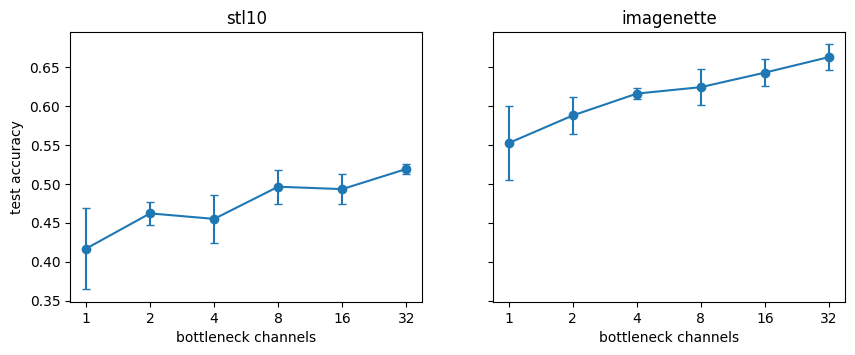

accuracy drop vs bottleneck 32


dataset,imagenette,stl10
bottleneck,,
1,0.1106,0.1025
2,0.0751,0.0571
4,0.0470,0.0642
8,0.0387,0.0228
16,0.0200,0.0259
32,0.0000,0.0000


smallest bottleneck within 1% of the widest: {'imagenette': 32, 'stl10': 32}


mean     std
dataset    bottleneck retina_layers cortex_layers                
imagenette 1          2             2              0.5526  0.0472
           2          1             2              0.5802  0.0127
                                    4              0.7109  0.0133
                      2             2              0.5881  0.0240
                                    4              0.6819  0.0127
           4          2             2              0.6162  0.0067
           8          2             2              0.6245  0.0230
           16         1             2              0.6448  0.0108
                                    4              0.7084  0.0090
                      2             2              0.6432  0.0177
                                    4              0.6843  0.0054
           32         2             2              0.6632  0.0162
stl10      1          2             2              0.4167  0.0525
           2          1             2              0.4712  0.0161
                                    4              0.5948  0.0186
                      2             2              0.4621  0.0152
                                    4              0.5851  0.0128
           4          2             2              0.4550  0.0304
           8          2             2              0.4964  0.0217
           16         1             2              0.5281  0.0283
                                    4              0.5722  0.0109
                      2             2              0.4933  0.0193
                                    4              0.5510  0.0109
           32         2             2              0.5192  0.0065

In [6]:
df = pd.read_csv(RESULTS_CSV)
if RERUNS_CSV.exists():  # collapsed runs are replaced by their rerun (lr / 3)
    rr = pd.read_csv(RERUNS_CSV)
    df = pd.concat([df.merge(rr[KEY], on=KEY, how='left', indicator=True).query("_merge == 'left_only'").drop(columns='_merge'),
                    rr.drop(columns='lr')], ignore_index=True)
keys = ['dataset', 'bottleneck', 'retina_layers', 'cortex_layers']
summary = df.groupby(keys).test_acc.agg(['mean', 'std']).round(4)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, ds in zip(axes, DATASETS):
    g = summary.xs((ds, 2, 2), level=['dataset', 'retina_layers', 'cortex_layers'])
    ax.errorbar(g.index, g['mean'], g['std'], marker='o', capsize=3)
    ax.set(xscale='log', xticks=BOTTLENECKS, xticklabels=BOTTLENECKS, title=ds, xlabel='bottleneck channels')
    ax.minorticks_off()
axes[0].set_ylabel('test accuracy')
plt.show()

# H3: accuracy drop w.r.t. the widest bottleneck, and the narrowest width within TOL of it.
TOL = 0.01
main = summary.xs((2, 2), level=['retina_layers', 'cortex_layers'])['mean'].unstack('dataset')
drop = (main.loc[BOTTLENECKS[-1]] - main).round(4)
print('accuracy drop vs bottleneck', BOTTLENECKS[-1])
display(drop)
print(f'smallest bottleneck within {TOL:.0%} of the widest:', (drop <= TOL).idxmax().to_dict())
summary


## Learned filters

Receptive field (RF) of each retina output channel (`retina_layers * 8 + 1` pixels wide): gradient of the channel's activation at the image centre with respect to the input, averaged over 256 natural images. This is the paper's linear RF estimate except for the probe: the paper uses a blank image, but in our networks most retina units are silent on a flat image (a check on a trained net gave 7 silent channels out of 8), so the blank-image gradient is zero. Each RF is classified with two tools:

- **Orientation selectivity index (OSI)**, as in App. A of the paper: strongest response to a rectangular bar at the preferred orientation divided by the strongest response at the orthogonal one (about 1 for isotropic RFs, larger for oriented ones; the paper reports 1.56 for the retina output, 3.05 for the first cortical layer, 1.97 for random RFs).
- **Fit quality ($R^2$) of an isotropic difference of Gaussians (DoG) and of a Gabor**.

Label: `center-surround` if OSI < `OSI_THR` and the DoG fits well (not worse than the Gabor by more than `R2_TOL`); `oriented` if OSI >= `OSI_THR` and the Gabor fits better than the DoG; `dead` if the gradient is zero; `other` otherwise. Thresholds are set on synthetic filters only, before looking at learned ones.


In [7]:
def load_model(ds, cfg, seed):
    tag = f"{ds}_b{cfg['bottleneck']}_r{cfg['retina_layers']}_c{cfg['cortex_layers']}_s{seed}"
    model = RetinaCortexNet(1 if GRAYSCALE else 3, 10, **cfg)
    model.load_state_dict(torch.load(CKPT_DIR / f'{tag}.pt', map_location='cpu'))
    return model.to(DEVICE).eval()

def probe_images(ds, n=256):
    x = raw_splits(ds)[1][0]
    idx = torch.randperm(len(x), generator=torch.Generator().manual_seed(0))[:n]
    return x[idx].float().div(255).to(DEVICE)

def retina_rfs(model, images, size=IMG_SIZE):
    """Linear RF of each retina output channel at the image centre: gradient w.r.t. the input, averaged over natural images.
    The paper uses a blank image; in our nets most units are silent on a flat image (ReLU, negative biases), so the blank-image gradient is 0."""
    n_conv = sum(isinstance(m, nn.Conv2d) for m in model.retina)
    c, h = size // 2, n_conv * (KERNEL - 1) // 2
    x = images.clone().requires_grad_(True)
    out = model.retina(x)
    rfs = []
    for ch in range(out.shape[1]):
        g, = torch.autograd.grad(out[:, ch, c, c].sum(), x, retain_graph=True)
        rfs.append((g.mean(0).mean(0) )[c - h:c + h + 1, c - h:c + h + 1].cpu().numpy())
    return np.stack(rfs)

def plot_filters(rfs, labels=None, ncols=8, title=''):
    nrows = int(np.ceil(len(rfs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.5, nrows * 1.6), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for i, (ax, f) in enumerate(zip(axes.ravel(), rfs)):
        m = max(np.abs(f).max(), 1e-12)
        ax.imshow(f, cmap='RdBu', vmin=-m, vmax=m)
        if labels is not None:
            ax.set_title(labels[i], fontsize=7)
    fig.suptitle(title)
    plt.show()


In [8]:
OSI_THR, R2_MIN, R2_TOL = 2.0, 0.5, 0.05
LABELS = ['center-surround', 'oriented', 'other', 'dead']

def _grid(n):
    yy, xx = np.mgrid[:n, :n].astype(float) - (n - 1) / 2
    return xx, yy

def orientation_index(rf, n_orient=12, widths=(1, 2, 3, 4, 5, 6)):
    """Paper App. A: best bar response at the preferred orientation / best response at the orthogonal one."""
    n = rf.shape[0]
    xx, yy = _grid(n)
    offsets = np.arange(-(n // 2), n // 2 + 1)
    resp = np.zeros((len(widths), n_orient, len(offsets)))
    for j in range(n_orient):
        th = j * np.pi / n_orient
        u = xx * np.cos(th) + yy * np.sin(th)
        for i, w in enumerate(widths):
            bars = np.abs(u[None] - offsets[:, None, None]) <= w / 2
            resp[i, j] = np.abs(bars.reshape(len(offsets), -1) @ rf.ravel())
    i, j, _ = np.unravel_index(resp.argmax(), resp.shape)
    s = resp[i].max(axis=1)
    perp = s[(j + n_orient // 2) % n_orient]
    return s[j] / max(perp, 1e-8 * s[j]), j * np.pi / n_orient

def _dog(p, xx, yy):
    x0, y0, sc, ss, a, k = p
    r2 = (xx - x0) ** 2 + (yy - y0) ** 2
    return a * (np.exp(-r2 / (2 * sc ** 2)) - k * np.exp(-r2 / (2 * ss ** 2)))

def _gabor(p, xx, yy):
    x0, y0, sx, sy, th, f, ph, a = p
    u = (xx - x0) * np.cos(th) + (yy - y0) * np.sin(th)
    v = -(xx - x0) * np.sin(th) + (yy - y0) * np.cos(th)
    return a * np.exp(-u ** 2 / (2 * sx ** 2) - v ** 2 / (2 * sy ** 2)) * np.cos(2 * np.pi * f * u + ph)

def _best_r2(fn, starts, lo, hi, rf, xx, yy):
    sst = ((rf - rf.mean()) ** 2).sum()
    best = -np.inf
    for p0 in starts:
        res = least_squares(lambda p: (fn(p, xx, yy) - rf).ravel(), p0, bounds=(lo, hi), max_nfev=200)
        best = max(best, 1 - (2 * res.cost) / sst)
    return best

def filter_stats(rf):
    n = rf.shape[0]
    if np.abs(rf).max() < 1e-10:
        return dict(osi=np.nan, r2_dog=np.nan, r2_gabor=np.nan, label='dead')
    rf = rf / np.abs(rf).max()
    xx, yy = _grid(n)
    osi, th = orientation_index(rf)
    sign = 1.0 if rf.flat[np.abs(rf).argmax()] > 0 else -1.0
    s = n / 10
    r2_dog = _best_r2(
        _dog, [[0, 0, sc, 2.5 * sc, sign, 0.8] for sc in (s, 1.6 * s)],
        [-n / 4, -n / 4, 0.7, 0.7, -3, 0.2], [n / 4, n / 4, n / 2, n, 3, 2], rf, xx, yy)
    r2_gabor = _best_r2(
        _gabor, [[0, 0, n / 5, n / 5, t, f, ph, sign] for t in (th, th + np.pi / 2) for f in (0.1, 0.2) for ph in (0, np.pi / 2)],
        [-n / 3, -n / 3, 0.7, 0.7, -2 * np.pi, 0.05, -2 * np.pi, -3], [n / 3, n / 3, n, n, 2 * np.pi, 0.5, 2 * np.pi, 3], rf, xx, yy)
    if osi < OSI_THR and r2_dog >= R2_MIN and r2_dog >= r2_gabor - R2_TOL:
        label = 'center-surround'
    elif osi >= OSI_THR and r2_gabor >= R2_MIN and r2_gabor > r2_dog:
        label = 'oriented'
    else:
        label = 'other'
    return dict(osi=osi, r2_dog=r2_dog, r2_gabor=r2_gabor, label=label)

def filter_type(kernel_2d):
    return filter_stats(np.asarray(kernel_2d, dtype=float))['label']


In [9]:
# Sanity check of the classifier on synthetic 17x17 filters (ground truth known), with 10% additive noise.
rng = np.random.default_rng(0)
xx, yy = _grid(17)
def synth(kind):
    if kind == 'center-surround':
        sc = rng.uniform(1.5, 3)
        rf = _dog([rng.uniform(-1, 1), rng.uniform(-1, 1), sc, sc * rng.uniform(1.8, 3), rng.choice([-1, 1]), rng.uniform(0.6, 1.0)], xx, yy)
    elif kind == 'oriented':
        rf = _gabor([rng.uniform(-1, 1), rng.uniform(-1, 1), rng.uniform(2.5, 4.5), rng.uniform(2.5, 4.5), rng.uniform(0, np.pi),
                     rng.uniform(0.08, 0.2), rng.uniform(0, 2 * np.pi), 1], xx, yy)
    else:
        return rng.standard_normal((17, 17))
    return rf / np.abs(rf).max() + 0.1 * rng.standard_normal((17, 17))

check = pd.DataFrame([dict(truth=k, pred=filter_type(synth(k))) for k in ['center-surround', 'oriented', 'noise'] for _ in range(40)])
pd.crosstab(check.truth, check.pred)


pred,center-surround,oriented,other
truth,,,
center-surround,40,0,0
noise,0,0,40
oriented,0,40,0


In [10]:
def analyse_filters(only=None):
    rows = []
    for ds in DATASETS:
        images = probe_images(ds)
        for cfg, s in itertools.product(CONFIGS, SEEDS):
            if only is not None and (ds, cfg['bottleneck'], cfg['retina_layers'], cfg['cortex_layers'], s) not in only:
                continue
            for ch, rf in enumerate(retina_rfs(load_model(ds, cfg, s), images)):
                rows.append(dict(dataset=ds, seed=s, channel=ch, **cfg, **filter_stats(rf)))
    return pd.DataFrame(rows)

if FILTERS_CSV.exists():
    filters_df = pd.read_csv(FILTERS_CSV)
    if RERUNS_CSV.exists():  # refresh only the networks that were retrained after a collapse
        stale = set(map(tuple, pd.read_csv(RERUNS_CSV)[KEY].values))
        fresh = analyse_filters(stale)
        old = filters_df.merge(fresh[KEY].drop_duplicates(), on=KEY, how='left', indicator=True)
        filters_df = pd.concat([old.query("_merge == 'left_only'").drop(columns='_merge'), fresh], ignore_index=True)
        filters_df.to_csv(FILTERS_CSV, index=False)
else:
    filters_df = analyse_filters()
    filters_df.to_csv(FILTERS_CSV, index=False)
filters_df.groupby('label').size()


label
center-surround     11
dead               137
oriented           264
other              290
dtype: int64

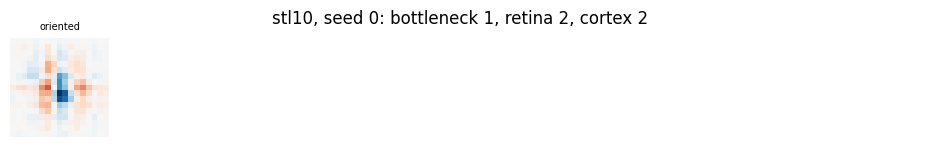

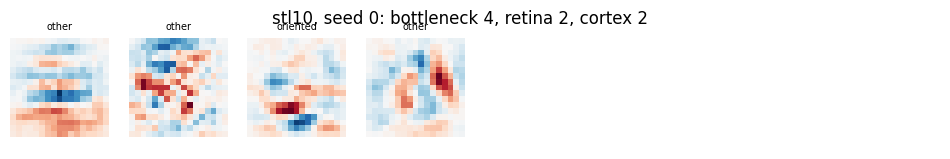

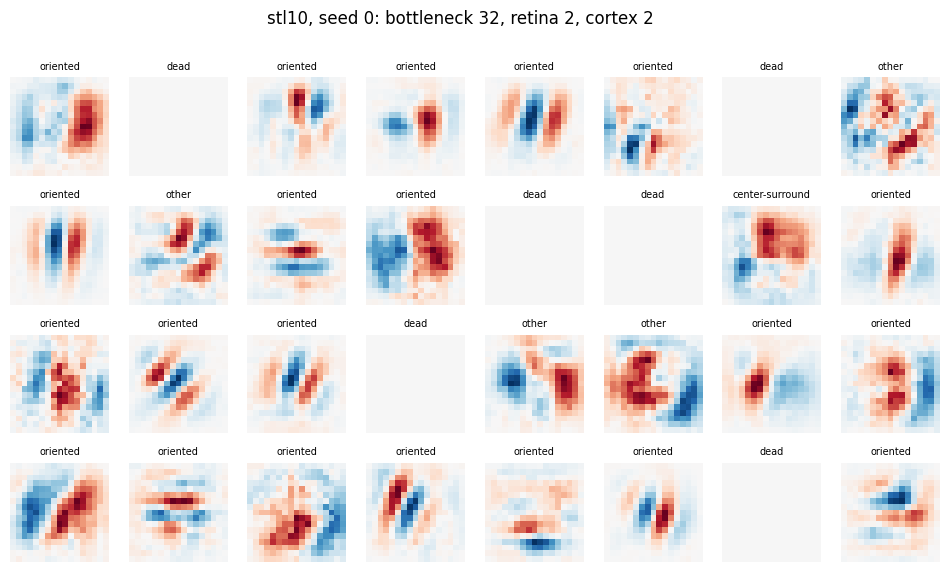

In [11]:
def show_rfs(ds, cfg, seed=0):
    rfs = retina_rfs(load_model(ds, cfg, seed), probe_images(ds))
    labels = [filter_type(rf) for rf in rfs]
    plot_filters(rfs, labels, title=f"{ds}, seed {seed}: bottleneck {cfg['bottleneck']}, retina {cfg['retina_layers']}, cortex {cfg['cortex_layers']}")

for b in (1, 4, 32):
    show_rfs(DATASETS[0], dict(bottleneck=b, retina_layers=2, cortex_layers=2))


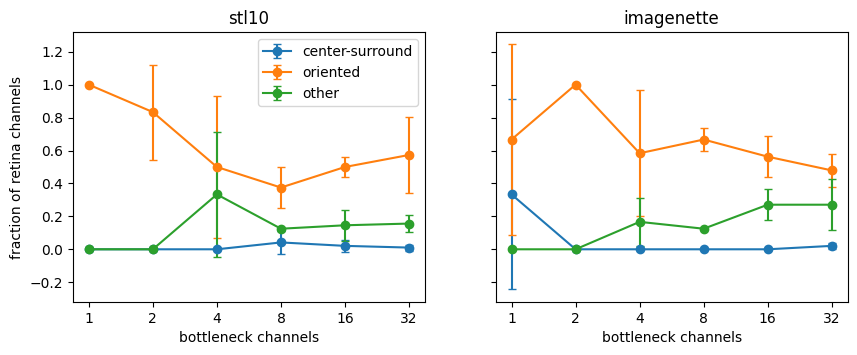

label                                             center-surround        \
                                                             mean   std   
dataset    bottleneck retina_layers cortex_layers                         
imagenette 1          2             2                        0.33  0.58   
           2          1             2                        0.00  0.00   
                                    4                        0.00  0.00   
                      2             2                        0.00  0.00   
                                    4                        0.00  0.00   
           4          2             2                        0.00  0.00   
           8          2             2                        0.00  0.00   
           16         1             2                        0.02  0.04   
                                    4                        0.00  0.00   
                      2             2                        0.00  0.00   
                                    4                        0.06  0.06   
           32         2             2                        0.02  0.02   
stl10      1          2             2                        0.00  0.00   
           2          1             2                        0.00  0.00   
                                    4                        0.00  0.00   
                      2             2                        0.00  0.00   
                                    4                        0.00  0.00   
           4          2             2                        0.00  0.00   
           8          2             2                        0.04  0.07   
           16         1             2                        0.00  0.00   
                                    4                        0.00  0.00   
                      2             2                        0.02  0.04   
                                    4                        0.02  0.04   
           32         2             2                        0.01  0.02   

label                                             oriented       other        \
                                                      mean   std  mean   std   
dataset    bottleneck retina_layers cortex_layers                              
imagenette 1          2             2                 0.67  0.58  0.00  0.00   
           2          1             2                 0.00  0.00  1.00  0.00   
                                    4                 0.00  0.00  1.00  0.00   
                      2             2                 1.00  0.00  0.00  0.00   
                                    4                 0.67  0.29  0.17  0.29   
           4          2             2                 0.58  0.38  0.17  0.14   
           8          2             2                 0.67  0.07  0.12  0.00   
           16         1             2                 0.31  0.12  0.60  0.16   
                                    4                 0.00  0.00  0.88  0.06   
                      2             2                 0.56  0.12  0.27  0.10   
                                    4                 0.17  0.04  0.50  0.11   
           32         2             2                 0.48  0.10  0.27  0.15   
stl10      1          2             2                 1.00  0.00  0.00  0.00   
           2          1             2                 0.00  0.00  1.00  0.00   
                                    4                 0.00  0.00  0.83  0.29   
                      2             2                 0.83  0.29  0.00  0.00   
                                    4                 0.50  0.50  0.33  0.29   
           4          2             2                 0.50  0.43  0.33  0.38   
           8          2             2                 0.38  0.12  0.12  0.00   
           16         1             2                 0.19  0.06  0.81  0.06   
                                    4                 0.06  0.06  0.88  0.06   
                      2             2                 

In [12]:
per_seed = (filters_df.groupby(keys + ['seed']).label.value_counts(normalize=True).unstack(fill_value=0)
            .reindex(columns=LABELS, fill_value=0))
per_seed['osi'] = filters_df.groupby(keys + ['seed']).osi.mean()
per_cfg = per_seed.groupby(keys).agg(['mean', 'std'])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, ds in zip(axes, DATASETS):
    g = per_cfg.xs((ds, 2, 2), level=['dataset', 'retina_layers', 'cortex_layers'])
    for lab in LABELS[:3]:
        ax.errorbar(g.index, g[(lab, 'mean')], g[(lab, 'std')], marker='o', capsize=3, label=lab)
    ax.set(xscale='log', xticks=BOTTLENECKS, xticklabels=BOTTLENECKS, title=ds, xlabel='bottleneck channels')
    ax.minorticks_off()
axes[0].set_ylabel('fraction of retina channels')
axes[0].legend()
plt.show()

per_cfg.round(2)


In [13]:
# Depth ablation at bottleneck 2 and 16 (mean over seeds): accuracy, share of center-surround / oriented channels, mean OSI.
depth = (summary['mean'].rename('acc').to_frame()
         .join(per_seed.groupby(keys)[['center-surround', 'oriented', 'osi']].mean())
         .loc[lambda d: d.index.get_level_values('bottleneck').isin([2, 16])]
         .sort_index(level=['dataset', 'bottleneck', 'retina_layers', 'cortex_layers']).round(3))
depth


acc  center-surround  \
dataset    bottleneck retina_layers cortex_layers                           
imagenette 2          1             2              0.580            0.000   
                                    4              0.711            0.000   
                      2             2              0.588            0.000   
                                    4              0.682            0.000   
           16         1             2              0.645            0.021   
                                    4              0.708            0.000   
                      2             2              0.643            0.000   
                                    4              0.684            0.062   
stl10      2          1             2              0.471            0.000   
                                    4              0.595            0.000   
                      2             2              0.462            0.000   
                                    4              0.585            0.000   
           16         1             2              0.528            0.000   
                                    4              0.572            0.000   
                      2             2              0.493            0.021   
                                    4              0.551            0.021   

                                                   oriented    osi  
dataset    bottleneck retina_layers cortex_layers                   
imagenette 2          1             2                 0.000  2.313  
                                    4                 0.000  2.624  
                      2             2                 1.000  3.144  
                                    4                 0.667  3.399  
           16         1             2                 0.312  3.106  
                                    4                 0.000  2.250  
                      2             2                 0.562  4.057  
                                    4                 0.167  2.062  
stl10      2          1             2                 0.000  1.777  
                                    4                 0.000  1.914  
                      2             2                 0.833  3.218  
                                    4                 0.500  2.989  
           16         1             2                 0.188  3.439  
                                    4                 0.062  2.695  
                      2             2                 0.500  4.262  
                                    4                 0.333  2.763

## Retina filters without labels

The `center-surround` / `oriented` labels depend on thresholds and on two parametric fits. This section looks at the quantity they are built on, the OSI of the non-dead retina channels, so that the reading of H1 and H2 does not rest on the labels alone. Label counts are given instead of percentages because narrow bottlenecks have very few channels per cell (3 seeds x bottleneck width). Reference values from the paper: OSI 1.56 for the retina output, 3.05 for the first cortical layer, 1.97 for random filters.

center-surround  oriented  \
dataset    bottleneck retina_layers cortex_layers                              
imagenette 1          2             2                            1         2   
           2          1             2                            0         0   
                                    4                            0         0   
                      2             2                            0         6   
                                    4                            0         4   
           4          2             2                            0         7   
           8          2             2                            0        16   
           16         1             2                            1        15   
                                    4                            0         0   
                      2             2                            0        27   
                                    4                            3         8   
           32         2             2                            2        46   
stl10      1          2             2                            0         3   
           2          1             2                            0         0   
                                    4                            0         0   
                      2             2                            0         5   
                                    4                            0         3   
           4          2             2                            0         6   
           8          2             2                            1         9   
           16         1             2                            0         9   
                                    4                            0         3   
                      2             2                            1        24   
                                    4                            1        16   
           32         2             2                            1        55   

                                                   other  dead  channels  \
dataset    bottleneck retina_layers cortex_layers                          
imagenette 1          2             2                  0     0         3   
           2          1             2                  6     0         6   
                                    4                  6     0         6   
                      2             2                  0     0         6   
                                    4                  1     1         6   
           4          2             2                  2     3        12   
           8          2             2                  3     5        24   
           16         1             2                 29     3        48   
                                    4                 42     6        48   
                      2             2                 13     8        48   
                                    4                 24    13        48   
           32         2             2                 26    22        96   
stl10      1          2             2                  0     0         3   
           2          1             2                  6     0         6   
                                    4                  5     1         6   
                      2             2                  0     1         6   
                                    4                  2     1         6   
           4          2             2                  4     2        12   
           8          2             2                  3    11        24   
           16         1             2                 39     0        48   
                                    4                 42     3        48   
                      2             2                  7    16        48   
                                    4                 15    16        48   
           32         2             2                 15    25        

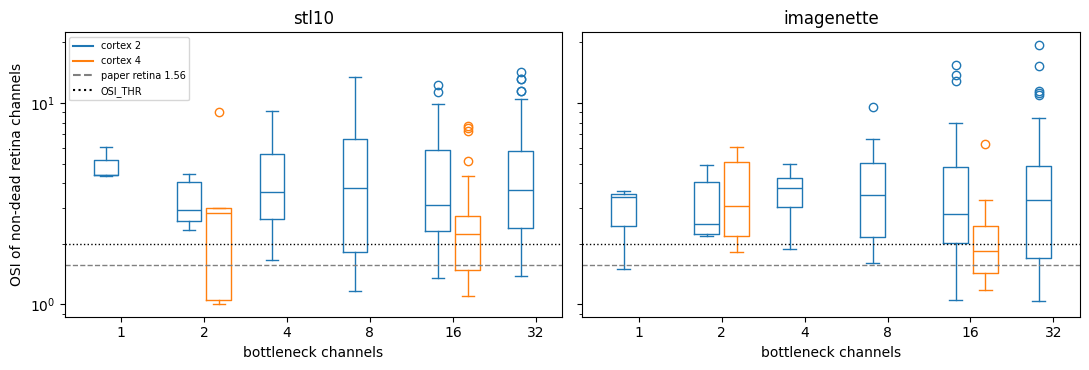

In [14]:
# Label counts (not percentages) and OSI of the live retina channels for every configuration, plus the OSI distribution per bottleneck.
live = filters_df[filters_df.label != 'dead']
counts = filters_df.groupby(keys).label.value_counts().unstack(fill_value=0).reindex(columns=LABELS, fill_value=0)
counts['channels'] = counts.sum(axis=1)
osi_tab = live.groupby(keys).osi.agg(live='count', osi_median='median')
osi_tab['share_osi_lt_2'] = live.groupby(keys).osi.apply(lambda x: (x < OSI_THR).mean())  # share of isotropic-looking channels
display(counts.join(osi_tab).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, ds in zip(axes, DATASETS):
    d = live[(live.dataset == ds) & (live.retina_layers == 2)]
    for j, b in enumerate(BOTTLENECKS):
        for cl, off, col in ((2, -0.18, 'C0'), (4, 0.18, 'C1')):  # cortex depth 4 exists only for bottleneck 2 and 16
            v = d[(d.bottleneck == b) & (d.cortex_layers == cl)].osi
            if len(v):
                ax.boxplot(v, positions=[j + off], widths=0.3, boxprops=dict(color=col), medianprops=dict(color=col),
                           whiskerprops=dict(color=col), capprops=dict(color=col), flierprops=dict(markeredgecolor=col))
    ax.axhline(1.56, ls='--', color='gray', lw=1)  # retina OSI of the paper
    ax.axhline(OSI_THR, ls=':', color='k', lw=1)   # threshold of the `oriented` label
    ax.set(xticks=range(len(BOTTLENECKS)), xticklabels=BOTTLENECKS, xlabel='bottleneck channels', title=ds, yscale='log')
axes[0].set_ylabel('OSI of non-dead retina channels')
axes[0].legend(handles=[plt.Line2D([], [], color='C0', label='cortex 2'), plt.Line2D([], [], color='C1', label='cortex 4'),
                        plt.Line2D([], [], color='gray', ls='--', label='paper retina 1.56'), plt.Line2D([], [], color='k', ls=':', label='OSI_THR')], fontsize=7)
plt.tight_layout()
plt.show()

## Positive control: the paper's own setup

H1 was not reproduced, and the sweep differs from the paper in several ways at once (STL-10 / Imagenette at 96x96 with 4,500-8,500 training images, max-pooling and a global-average-pool head instead of a flattened FC 1024, our RF probe). Without a run in the paper's own setup it is not possible to say whether the non-reproduction comes from those differences or from the training and analysis pipeline (RF probe, DoG/Gabor labels, thresholds). This control trains the architecture of Lindsey et al. on their data and analyses it with exactly the same code as the main sweep.

**Setup.** Grayscale CIFAR-10 at 32x32 (45,000 training images, 5,000 validation, official test set), retina of 2 convolutions with `bottleneck` channels at the output, cortex of 2 or 4 convolutions, **no pooling**, flatten, FC 1024, FC 10. Everything else as in the main sweep (9x9 kernels, 32 channels, Glorot, RMSProp lr 1e-3, 20 epochs, batch 32, best-validation checkpoint, horizontal flip, collapse rule). Bottlenecks 1, 4 and 32, cortex depth 2 and 4, 3 seeds. The retina receptive fields are computed with two probes: the gradient averaged over 256 natural test images (the probe of the main sweep) and the gradient at a flat mid-gray image (the paper's blank-image probe).

**Prediction and decision rule (written before running).**
- P1 (the pipeline can see the effect): at bottleneck 1 and 4 with cortex 4 at least 30% of the live retina channels are labelled `center-surround`, against less than 10% at bottleneck 32 with cortex 2. P1 is judged with the blank-image probe (the paper's) and with the natural-image probe (the sweep's). A smoke test before the run showed that after 1 epoch every retina channel is silent on a flat image, as already seen in the main sweep, so the blank-image probe may leave few live channels: **if fewer than 30% of the channels are live under the blank probe, that probe is not informative and P1 is judged on the natural-image probe alone** (this rule was added after the smoke test and before the control was run).
- If P1 holds, the pipeline detects the effect where the paper reports it, and the missing effect on STL-10 and Imagenette is attributable to the differences in data and architecture (not tested individually).
- If P1 fails but the share of channels with OSI < 2 is clearly larger at narrow bottleneck and deep cortex than at the wide one, the `center-surround` label is too strict, and the OSI-based reading of the main sweep is the one to report.
- If neither holds, the paper's result is not obtained in its own setup with this pipeline, and the non-reproduction on STL-10 and Imagenette cannot be attributed to the data or the architecture: it would point to the pipeline (or to a fragile result), and H1 would have to be reported as untested rather than as not reproduced.
- P2: the natural-image probe gives the same ordering of the configurations as the blank-image probe.

In [15]:
# Positive control: the paper's architecture (no pooling, flatten + FC 1024) on grayscale CIFAR-10 at 32x32, same recipe and analysis as the sweep.
CTRL_BOTTLENECKS, CTRL_CORTEX, CTRL_SIZE = [1, 4, 32], [2, 4], 32
CTRL_CSV, CTRL_CKPT = Path('results/control_cifar10.csv'), Path('checkpoints_cifar')
CTRL_COLLAPSE_VAL, CTRL_RERUN_LR = 0.2, LR / 3  # same collapse rule as the main sweep

class PaperNet(nn.Module):
    # Lindsey et al.: retina (2 convs, `bottleneck` channels at the output), cortex (`cortex_layers` convs), no pooling, FC 1024, FC 10
    def __init__(self, bottleneck, cortex_layers, size=CTRL_SIZE, in_ch=1, num_classes=10, retina_layers=2, kernel=KERNEL, width=32):
        super().__init__()
        pad = kernel // 2
        retina, c = [], in_ch
        for i in range(retina_layers):
            out = bottleneck if i == retina_layers - 1 else width
            retina += [nn.Conv2d(c, out, kernel, padding=pad), nn.ReLU()]
            c = out
        cortex = []
        for _ in range(cortex_layers):
            cortex += [nn.Conv2d(c, width, kernel, padding=pad), nn.ReLU()]
            c = width
        self.retina, self.cortex = nn.Sequential(*retina), nn.Sequential(*cortex)
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(width * size * size, 1024), nn.ReLU(), nn.Linear(1024, num_classes))
        for m in self.modules():  # Glorot-uniform and zero biases, as in the main sweep
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.head(self.cortex(self.retina((x - 0.5) / 0.25)))  # same input centring as the main sweep

_CIFAR = {}

def cifar_splits():
    # decode once: grayscale, uint8 (train 50,000 / test 10,000)
    if not _CIFAR:
        tf = T.Compose([T.Grayscale(), T.PILToTensor()])
        for name, train_split in (('train', True), ('test', False)):
            ds = torchvision.datasets.CIFAR10(DATA_ROOT / 'cifar10', train=train_split, transform=tf, download=True)
            _CIFAR[name] = (torch.stack([x for x, _ in ds]), torch.tensor(ds.targets))
    return _CIFAR['train'], _CIFAR['test']

def cifar_loaders(seed):
    # 10% of the training set held out for validation (split depends on the seed), flip augmentation only, as in the sweep
    (x_tr, y_tr), (x_te, y_te) = cifar_splits()
    n_val = len(y_tr) // 10
    perm = torch.randperm(len(y_tr), generator=torch.Generator().manual_seed(seed))
    tr, va = perm[n_val:], perm[:n_val]
    return GPULoader(x_tr[tr], y_tr[tr], True, flip=True), GPULoader(x_tr[va], y_tr[va], False), GPULoader(x_te, y_te, False)

def ctrl_run(bottleneck, cortex_layers, seed, lr):
    global LR
    lr_orig, LR = LR, lr
    try:
        set_seed(seed)
        train_dl, val_dl, test_dl = cifar_loaders(seed)
        model = PaperNet(bottleneck, cortex_layers).to(DEVICE)
        val_acc = train(model, train_dl, val_dl)
        return model, val_acc, evaluate(model, test_dl)
    finally:
        LR = lr_orig

CTRL_CKPT.mkdir(exist_ok=True)
CTRL_CSV.parent.mkdir(exist_ok=True)
for b, cl, s in itertools.product(CTRL_BOTTLENECKS, CTRL_CORTEX, SEEDS):
    tag = f'cifar10_b{b}_c{cl}_s{s}'
    if (CTRL_CKPT / f'{tag}.pt').exists():
        continue
    t0 = time.time()
    model, val_acc, test_acc = ctrl_run(b, cl, s, LR)
    first = None
    if val_acc < CTRL_COLLAPSE_VAL:  # collapsed to chance: retrain once with lr / 3, keep the first result in the CSV
        first = val_acc
        model, val_acc, test_acc = ctrl_run(b, cl, s, CTRL_RERUN_LR)
    torch.save(model.state_dict(), CTRL_CKPT / f'{tag}.pt')
    row = dict(dataset='cifar10', bottleneck=b, cortex_layers=cl, seed=s, val_acc=val_acc, test_acc=test_acc, first_val_acc=first, time_s=time.time() - t0)
    pd.DataFrame([row]).to_csv(CTRL_CSV, mode='a', header=not CTRL_CSV.exists(), index=False)

In [16]:
# Retina receptive fields of the control networks with two probes (natural images; flat mid-gray image = the paper's blank-image probe), then the same labels as the sweep.
CTRL_FILTERS_CSV = Path('results/control_filters.csv')

def ctrl_model(b, cl, s):
    model = PaperNet(b, cl)
    model.load_state_dict(torch.load(CTRL_CKPT / f'cifar10_b{b}_c{cl}_s{s}.pt', map_location='cpu'))
    return model.to(DEVICE).eval()

if CTRL_FILTERS_CSV.exists():
    ctrl_filters = pd.read_csv(CTRL_FILTERS_CSV)
else:
    nat = cifar_splits()[1][0][torch.randperm(10000, generator=torch.Generator().manual_seed(0))[:256]].float().div(255).to(DEVICE)
    blank = torch.full((1, 1, CTRL_SIZE, CTRL_SIZE), 0.5, device=DEVICE)
    rows = []
    for b, cl, s in itertools.product(CTRL_BOTTLENECKS, CTRL_CORTEX, SEEDS):
        model = ctrl_model(b, cl, s)
        for probe, imgs in (('natural', nat), ('blank', blank)):
            for ch, rf in enumerate(retina_rfs(model, imgs, size=CTRL_SIZE)):
                rows.append(dict(probe=probe, seed=s, channel=ch, bottleneck=b, cortex_layers=cl, **filter_stats(rf)))
    ctrl_filters = pd.DataFrame(rows)
    ctrl_filters.to_csv(CTRL_FILTERS_CSV, index=False)
ctrl_filters.groupby(['probe', 'label']).size().unstack(fill_value=0)

label,center-surround,dead,oriented,other
probe,,,,
blank,7,208,3,4
natural,10,169,23,20


test accuracy (mean, std over seeds):


mean    std  count
bottleneck cortex_layers                     
1          2              0.672  0.004      3
           4              0.652  0.079      3
4          2              0.605  0.024      3
           4              0.555  0.022      3
32         2              0.594  0.021      3
           4              0.573  0.092      3

runs that collapsed and were retrained: 6


center-surround  oriented  other  dead  \
probe   bottleneck cortex_layers                                           
blank   1          2                            3         0      0     0   
                   4                            0         2      1     0   
        4          2                            1         0      0    11   
                   4                            3         0      0     9   
        32         2                            0         0      0    96   
                   4                            0         1      3    92   
natural 1          2                            2         0      1     0   
                   4                            0         2      1     0   
        4          2                            3         0      0     9   
                   4                            3         0      0     9   
        32         2                            1         4      0    91   
                   4                            1        17     18    60   

                                  channels  live  osi_median  share_osi_lt_2  \
probe   bottleneck cortex_layers                                               
blank   1          2                     3   3.0        1.32            1.00   
                   4                     3   3.0        5.66            0.00   
        4          2                    12   1.0        1.07            1.00   
                   4                    12   3.0        1.48            1.00   
        32         2                    96   NaN         NaN             NaN   
                   4                    96   4.0        2.59            0.25   
natural 1          2                     3   3.0        1.29            1.00   
                   4                     3   3.0        2.33            0.33   
        4          2                    12   3.0        1.48            1.00   
                   4                    12   3.0        1.54            1.00   
        32         2                    96   5.0        3.28            0.20   
                   4                    96  36.0        2.63            0.28   

                                  share_center_surround  
probe   bottleneck cortex_layers                         
blank   1          2                               1.00  
                   4                               0.00  
        4          2                               1.00  
                   4                               1.00  
        32         2                                NaN  
                   4                               0.00  
natural 1          2                               0.67  
                   4                               0.00  
        4          2                               1.00  
                   4                               1.00  
        32         2                               0.20  
                   4                               0.03

blank probe, live channels 14.0 of 222
  bottleneck <= 4, cortex 4: center-surround 3 of 6.0 live channels
  bottleneck 32, cortex 2:   center-surround 0 of 0.0 live channels
natural probe, live channels 53.0 of 222
  bottleneck <= 4, cortex 4: center-surround 3 of 6.0 live channels
  bottleneck 32, cortex 2:   center-surround 1 of 5.0 live channels


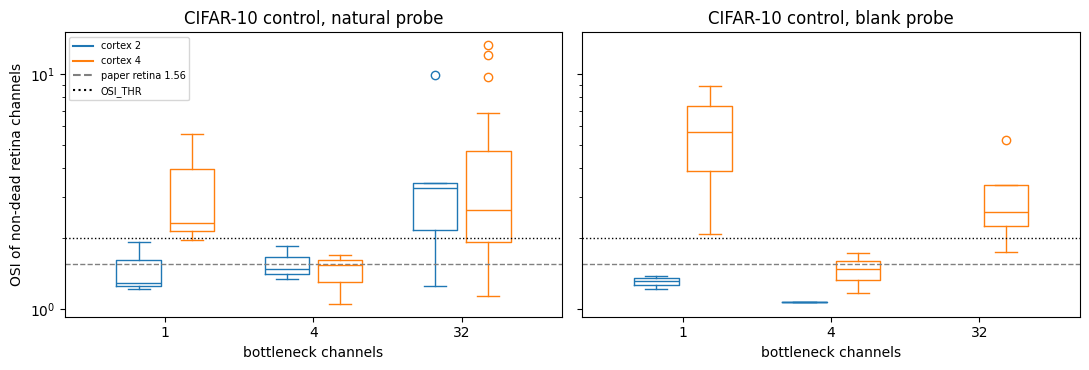

In [17]:
# Control analysis: accuracy, label counts and OSI per configuration and probe; P1 of the decision rule.
ctrl = pd.read_csv(CTRL_CSV)
print('test accuracy (mean, std over seeds):')
display(ctrl.groupby(['bottleneck', 'cortex_layers']).test_acc.agg(['mean', 'std', 'count']).round(3))
print('runs that collapsed and were retrained:', int(ctrl.first_val_acc.notna().sum()))

ck = ['probe', 'bottleneck', 'cortex_layers']
live_c = ctrl_filters[ctrl_filters.label != 'dead']
ctrl_counts = ctrl_filters.groupby(ck).label.value_counts().unstack(fill_value=0).reindex(columns=LABELS, fill_value=0)
ctrl_counts['channels'] = ctrl_counts.sum(axis=1)
ctrl_osi = live_c.groupby(ck).osi.agg(live='count', osi_median='median')
ctrl_osi['share_osi_lt_2'] = live_c.groupby(ck).osi.apply(lambda x: (x < OSI_THR).mean())
ctrl_tab = ctrl_counts.join(ctrl_osi)
ctrl_tab['share_center_surround'] = ctrl_tab['center-surround'] / ctrl_tab.live
display(ctrl_tab.round(2))

# P1: share of center-surround channels among the live ones, narrow + deep against wide + shallow, for both probes (and how many channels are live)
for probe in ['blank', 'natural']:
    pr = ctrl_tab.xs(probe)
    nd, ws = pr.loc[[(b, 4) for b in CTRL_BOTTLENECKS if b <= 4]], pr.loc[[(32, 2)]]
    print(f'{probe} probe, live channels {pr.live.sum()} of {pr.channels.sum()}')
    print(f'  bottleneck <= 4, cortex 4: center-surround {nd["center-surround"].sum()} of {nd.live.sum()} live channels')
    print(f'  bottleneck 32, cortex 2:   center-surround {ws["center-surround"].sum()} of {ws.live.sum()} live channels')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, probe in zip(axes, ['natural', 'blank']):
    d = live_c[live_c.probe == probe]
    for j, b in enumerate(CTRL_BOTTLENECKS):
        for cl, off, col in ((2, -0.18, 'C0'), (4, 0.18, 'C1')):
            v = d[(d.bottleneck == b) & (d.cortex_layers == cl)].osi
            if len(v):
                ax.boxplot(v, positions=[j + off], widths=0.3, boxprops=dict(color=col), medianprops=dict(color=col),
                           whiskerprops=dict(color=col), capprops=dict(color=col), flierprops=dict(markeredgecolor=col))
    ax.axhline(1.56, ls='--', color='gray', lw=1)
    ax.axhline(OSI_THR, ls=':', color='k', lw=1)
    ax.set(xticks=range(len(CTRL_BOTTLENECKS)), xticklabels=CTRL_BOTTLENECKS, xlabel='bottleneck channels', title=f'CIFAR-10 control, {probe} probe', yscale='log')
axes[0].set_ylabel('OSI of non-dead retina channels')
axes[0].legend(handles=[plt.Line2D([], [], color='C0', label='cortex 2'), plt.Line2D([], [], color='C1', label='cortex 4'),
                        plt.Line2D([], [], color='gray', ls='--', label='paper retina 1.56'), plt.Line2D([], [], color='k', ls=':', label='OSI_THR')], fontsize=7)
plt.tight_layout()
plt.show()

### Positive control: findings

Grayscale CIFAR-10 at 32x32, architecture of Lindsey et al. (no pooling, FC 1024), 18 runs (bottleneck 1, 4, 32; cortex 2, 4; 3 seeds), analysed with the code of the main sweep.

- **The paper's recipe is fragile in our hands.** Test accuracy is 0.56-0.67. 6 of 18 runs collapsed to chance at the first attempt (5 of them at bottleneck 1) and were retrained with lr / 3 as in the sweep. 76% of the retina channels are dead under the natural-image probe (169 of 222; 19.5% in the main sweep) and 94% under the flat-image probe (208 of 222). Only 53 channels are live under the natural probe and 14 under the flat one.
- **P1 is not met as written.** Both probes leave fewer than 30% of the channels live, so under the rule the flat-image probe is uninformative and P1 is judged on the natural-image probe: bottleneck 1 and 4 with cortex 4 have 3 of 6 live channels labelled `center-surround` (50%, above the 30% bar), but bottleneck 32 with cortex 2 has 1 of 5 (20%, not below 10%). Neither share is a reliable estimate on 5-6 live channels, so P1 is inconclusive by its own criterion.
- **The OSI shows the qualitative effect of the paper.** All live channels at bottleneck 4 are isotropic (OSI 1.05-1.86, median about 1.5, against 1.56 for the retina in the paper), as are those at bottleneck 1 with cortex 2 (1.21-1.93); at width 32 the median OSI is 3.3 with cortex 2 (5 live channels) and 2.6 with cortex 4 (36 live channels, range 1.1-13). In the main sweep the same code gave a median OSI of 3.6 (STL-10) and 3.8 (Imagenette) at bottleneck 4, with 10-11% of the live channels below OSI 2. So the pipeline returns isotropic retinal filters at a narrow bottleneck in the paper's setup and oriented ones in the reduced setup. There is no cortex-depth effect in the control (bottleneck 4: median about 1.5 with cortex 2 and with cortex 4).
- **Reading under the decision rule.** The first branch (P1) is not satisfied. The second branch (OSI clearly lower at narrow bottleneck and deep cortex than at the wide one) holds on the natural probe (4 of 6 live channels below OSI 2 against 1 of 5), but on very few channels. The tentative conclusion is that the pipeline is not blind to the effect, so the missing effect on STL-10 and Imagenette points to the differences in data and architecture (96x96 images, 4,500-8,500 training images, max-pooling and a global-average-pool head), which were not isolated one by one. H1 is therefore reported as *not reproduced in the reduced setting*, not as refuted, and the control is too underpowered (few live channels, collapses, low accuracy) to claim more.

## Discussion

For each hypothesis: expected outcome, observed outcome, explanation of any mismatch with the paper. Numbers: mean over 3 seeds, 96x96 grayscale, retina depth 2 and cortex depth 2 unless stated; shares are fractions of retina output channels by label (702 channels in total: 290 `other`, 264 `oriented`, 137 `dead`, 11 `center-surround`). The OSI averaged over non-dead channels is 3.5 (median 2.6); the paper reports 1.56 for the retina output, 3.05 for the first cortical layer and 1.97 for random filters.

- **H1 (narrow bottleneck + deep cortex -> center-surround retina filters): not reproduced.**
  - Only 11 of 702 channels (1.6%) are classified as center-surround, and none in the narrow-bottleneck, deep-cortex configuration that the hypothesis is about (bottleneck 2, cortex 4: 0 of 6 channels on each dataset). In that configuration the retina filters are mostly `oriented` (3 of 6 channels on STL-10, 4 of 6 on Imagenette, 1 dead channel each) and the median OSI of the live channels is 2.9 (STL-10) and 3.1 (Imagenette), 5 live channels each, against 1.56 for the retina and 3.05 for the first cortical layer in the paper. Counts and not percentages are given for these cells because a cell has only 6 channels (3 seeds x 2).
  - The conclusion does not depend on the DoG/Gabor labels (see "Retina filters without labels" above). Over all 565 live channels the median OSI is 2.6, against 1.56 in the paper, and 34% of them have OSI < 2. The `center-surround` label is conservative: it needs a DoG fit with R^2 >= 0.5 that is not worse than the Gabor fit, so isotropic filters with a poor DoG fit end up in `other` (median OSI 1.8), and the 11 `center-surround` channels have DoG and Gabor R^2 within 0.05 of each other, i.e. they are low-confidence labels. In OSI terms the share of isotropic channels is not larger at narrow bottlenecks either (cortex 2: 0-33% at bottleneck 1-2 on 3-6 live channels per cell, 10-31% at 4-8, 14-34% at 16-32).
  - The paper's claim therefore does not hold in this reduced setting. Why is only partly known: a positive control in the paper's own setup (section "Positive control: the paper's own setup") gives isotropic retinal filters at a narrow bottleneck (median OSI about 1.5 at bottleneck 4, against 3.6-3.8 in the sweep), so the analysis pipeline is not blind to the effect, but the control is underpowered (53 live channels of 222) and the differences between the two setups were not isolated one by one. Differences that could matter: far less training data (4.5k and 8.5k images instead of 50k), 96x96 instead of 32x32 inputs (the same 9x9 kernels cover a much smaller part of the scene; a 32x32 pilot also gave no center-surround filters), global average pooling plus a linear classifier instead of a flattened dense layer, 3 seeds instead of 10, and our RF probe (gradient averaged over natural images instead of a blank image).
- **H2 (wide bottleneck or shallow cortex -> oriented retina filters): partly supported.**
  - Shallow cortex: with the bottleneck fixed, cortex depth 2 gives more oriented filters than cortex depth 4 in all four comparisons (oriented channels, bottleneck 2: STL-10 5/6 vs 3/6, Imagenette 6/6 vs 4/6; bottleneck 16: STL-10 24/48 vs 16/48, Imagenette 27/48 vs 8/48). Cortex 4 mostly turns the difference into `other` and `dead`, not center-surround, so this agrees with the paper only in direction (a deeper cortex makes the retina less oriented), not with "shallow cortex -> oriented, deep cortex -> center-surround". The OSI shows the same direction: the share of channels with OSI < 2 is larger with cortex 4 than with cortex 2 in all four comparisons (bottleneck 2: STL-10 40% vs 0%, Imagenette 20% vs 0%, on 5-6 live channels; bottleneck 16: STL-10 38% vs 16%, Imagenette 66% vs 25%), so a deeper cortex does make the retina more isotropic, as in the paper, but the filters are not DoG-shaped.
  - Wide bottleneck: bottleneck 32 has 55/96 (STL-10) and 46/96 (Imagenette) oriented channels, but narrow bottlenecks are not different or are *more* oriented (bottleneck 1: 3/3 and 2/3 channels), so the expected bottleneck effect on filter geometry is absent or opposite.
  - Retina depth 1: most filters are `other` (60-100%); the 9x9 receptive field is small for the DoG/Gabor fits, so this label is not reliable.
- **H3 (accuracy drops little while the bottleneck stays above a threshold): not confirmed as a threshold; accuracy decreases gradually.**
  - Test accuracy for bottleneck 1, 2, 4, 8, 16, 32: STL-10 0.417, 0.462, 0.455, 0.496, 0.493, 0.519; Imagenette 0.553, 0.588, 0.616, 0.624, 0.643, 0.663. Doubling the bottleneck changes accuracy by -1 to +4.5 points step by step (the steps 2 to 4 and 8 to 16 are within noise), with no knee; overall, going from 32 to 1 channel costs about 10 points on both datasets. A "within 1 point of the widest" rule selects only the widest bottleneck on both datasets.
  - The paper also reports accuracy increasing with both bottleneck width and cortex depth; the cortex part is reproduced (bottleneck 2: cortex 4 vs 2 gives +12 points on STL-10 and +9 on Imagenette; bottleneck 16: +6 and +4).

### Limitations

- Absolute accuracy is low (0.42-0.71) because of the small training sets and the small network, and 20% of the retina channels are dead (never active), so the analysed filters are a subset of the trained ones.
- Training recipe: the first sweep used PyTorch defaults with Adam and produced dead and noisy filters; the recipe was then fixed to the paper's (Glorot, RMSProp, lr 1e-3, batch 32) after a validation-only pilot that also looked at filter health. 3 of 72 runs collapsed to chance level and were retrained once with lr / 3 (rule fixed after the sweep, raw results kept in `results.csv`). All reported numbers use the rerun values for those three runs.
- Filter labels depend on thresholds set on synthetic filters (100% accuracy there) and not validated against human labels on learned filters, and the `center-surround` label is strict (34% of the live channels have OSI < 2, 2% are labelled center-surround); the RF probe differs from the paper's blank-image gradient (silent units).
- Positive control: with the paper's architecture and recipe 76% of the retina channels are dead, 6 of 18 runs collapsed at the first attempt and accuracy is 0.56-0.67, so the control has few live channels (5-6 at the cells that matter) and its conclusions are tentative.
- Only 3 seeds (paper: 10), one architecture family, no ablation on kernel size or on the number of cortex channels.
